In [11]:
#Inviscid Burgers
path_DP='/users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Examples_analytical_exact/Ablation_Study/Burgers/burgers.npz'
path_ANS='/users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/NM_codes/Burgers_Periodic_SinSum/2026_01_10_1309_human/burgers.npz'
path_A='/users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/NM_codes/Burgers_Periodic_SinSumHalf/2025_12_23_1233/burgers.npz'

Loaded data with shape: (201, 128, 128)
Time range: 0.00 to 2.00
Plot saved to: burgers_1x4_plot.png


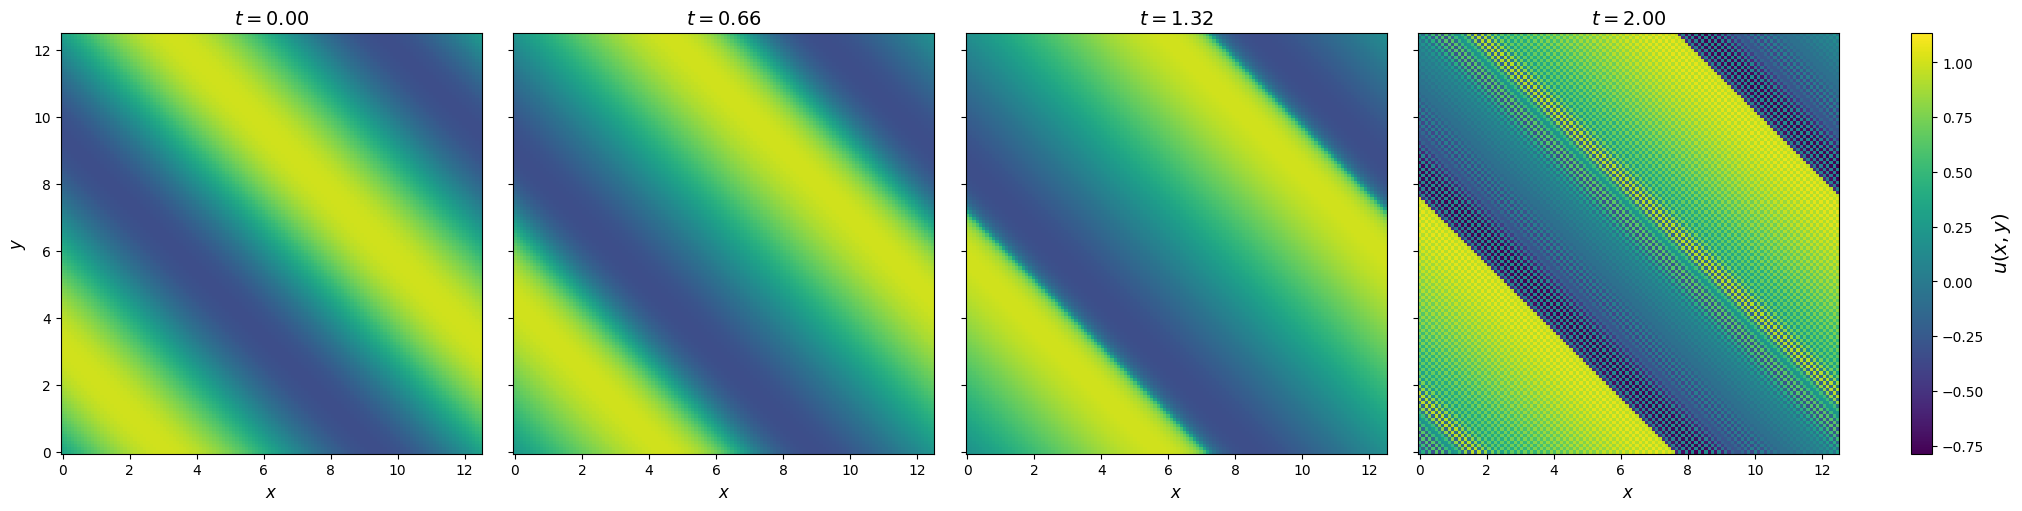

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import os

# ==========================================
# 1. Load Data
# ==========================================
# Ensure the script looks in the current directory for the file
file_path = path_DP

if not os.path.exists(file_path):
    raise FileNotFoundError(f"Could not find data file at: {file_path}")

data = np.load(file_path)
t = data['t']          # Shape: (NumSteps,)
x = data['x']          # Shape: (Nx,)
y = data['y']          # Shape: (Ny,)
usol = data['usol']    # Shape: (NumSteps, Nx, Ny)

print(f"Loaded data with shape: {usol.shape}")
print(f"Time range: {t[0]:.2f} to {t[-1]:.2f}")

# ==========================================
# 2. Setup Plotting Grid
# ==========================================
# Use indexing='ij' to match the (X, Y) order from the Julia export
X, Y = np.meshgrid(x, y, indexing='ij')

# Select 4 distinct time indices (Initial, 1/3, 2/3, Final)
# We select 4 to fill the 1x4 layout requested
n_t = len(t)
indices = [0, int(n_t * 0.33), int(n_t * 0.66), n_t - 1]

# ==========================================
# 3. Visualization
# ==========================================
fig, axes = plt.subplots(1, 4, figsize=(20, 5), constrained_layout=True)

# Determine global color limits for consistent comparison
vmin, vmax = np.min(usol), np.max(usol)

for i, idx in enumerate(indices):
    ax = axes[i]
    t_curr = t[idx]
    u_curr = usol[idx]
    
    # Plotting
    # Note: transpose u_curr if visualization looks rotated 90 degrees
    # due to specific meshgrid conventions, but 'ij' usually aligns 
    # with array[i, j] -> (x[i], y[j]).
    c = ax.pcolormesh(X, Y, u_curr, cmap='viridis', 
                      vmin=vmin, vmax=vmax, shading='auto')
    
    # Formatting
    ax.set_title(f"$t = {t_curr:.2f}$", fontsize=14)
    ax.set_xlabel("$x$", fontsize=12)
    ax.set_aspect('equal')
    
    if i == 0:
        ax.set_ylabel("$y$", fontsize=12)
    else:
        # Hide y-ticks for inner plots to reduce clutter
        ax.set_yticklabels([])

# Add a single colorbar for the whole figure
cbar = fig.colorbar(c, ax=axes, orientation='vertical', fraction=0.02, pad=0.04)
cbar.set_label("$u(x,y)$", fontsize=14)

# ==========================================
# 4. Save Figure
# ==========================================
output_path ="burgers_1x4_plot.png"
plt.savefig(output_path, dpi=300)
print(f"Plot saved to: {output_path}")
plt.show()

Loaded data with shape: (256, 256, 6)
Time steps available: [0.   0.25 0.66 1.   1.33 2.  ]
Plot saved to: burgers_muscl_summary.png


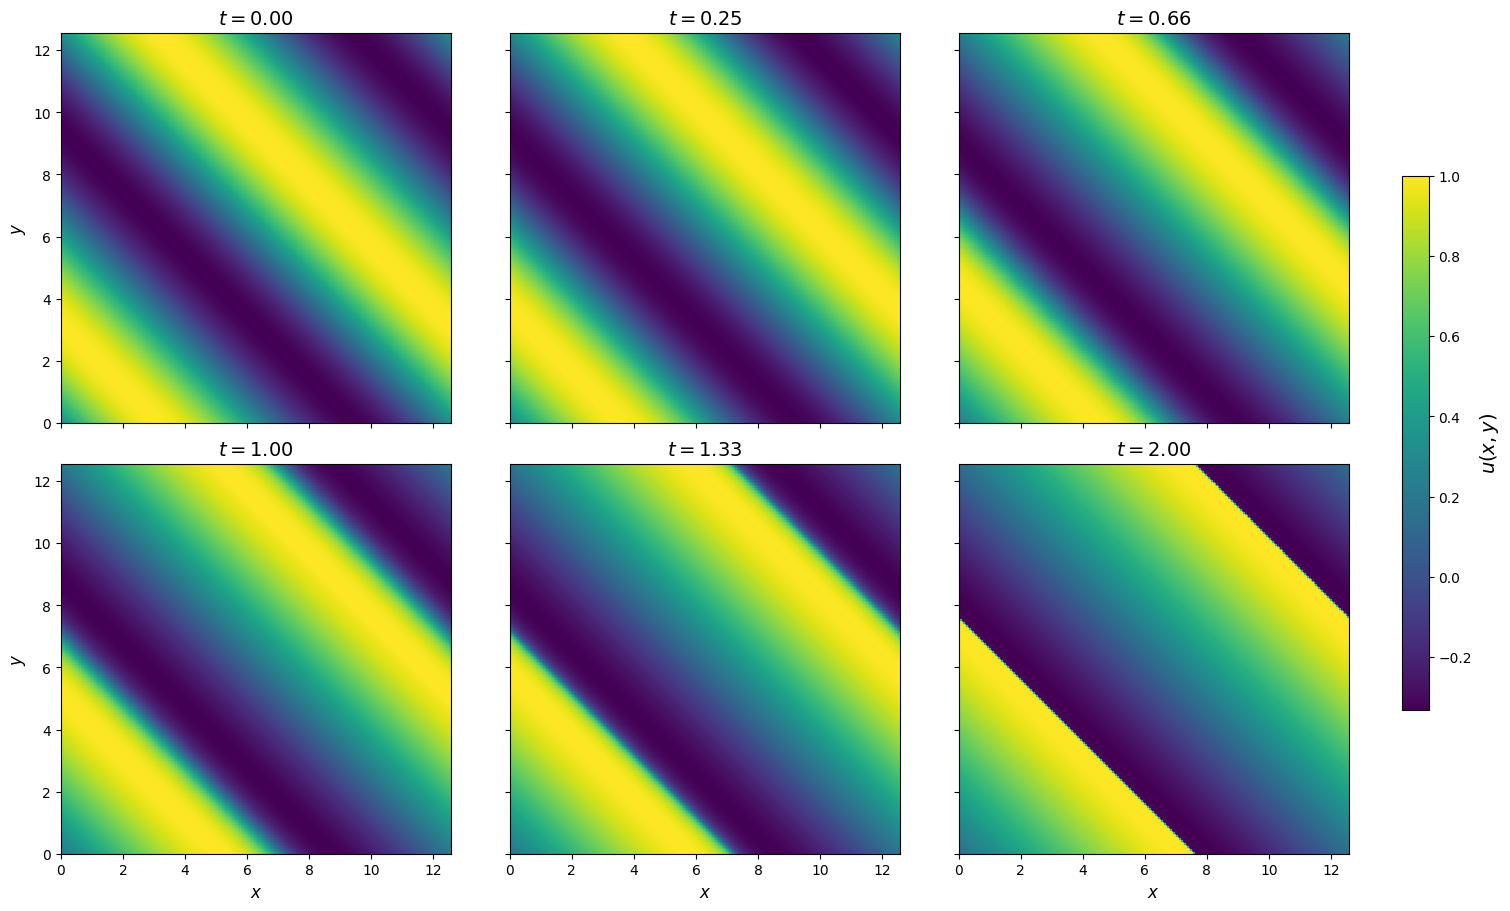

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import os

# ==========================================
# 1. Load Data
# ==========================================
file_path = path_ANS

if not os.path.exists(file_path):
    raise FileNotFoundError(f"Could not find data file at: {file_path}")

data = np.load(file_path)
t = data['t']      # Shape: (6,) -> [0.0, 0.25, 0.5, 1.0, 1.5, 2.0]
x = data['x']      # Shape: (256,)
y = data['y']      # Shape: (256,)
u = data['u']      # Shape: (256, 256, 6) -> (X, Y, Time)

print(f"Loaded data with shape: {u.shape}")
print(f"Time steps available: {t}")

# ==========================================
# 2. Setup Plotting Grid
# ==========================================
# Use indexing='ij' so that X[i,j] corresponds to x[i] and Y[i,j] to y[j]
# This matches the Julia array layout u[i, j, k]
X, Y = np.meshgrid(x, y, indexing='ij')

# ==========================================
# 3. Visualization (2x3 Grid)
# ==========================================
# We have 6 snapshots, so a 2 rows x 3 columns layout is perfect
fig, axes = plt.subplots(2, 3, figsize=(15, 9), constrained_layout=True)
axes = axes.flatten()  # Flatten to easily loop over 0..5

# Determine global color limits for consistent comparison across all times
vmin, vmax = np.min(u), np.max(u)

for k in range(len(t)):
    ax = axes[k]
    t_curr = t[k]
    
    # Extract 2D slice for the current time step
    # Shape is (X, Y), so we pass it directly to pcolormesh with X, Y
    u_curr = u[:, :, k]
    
    # Plotting
    c = ax.pcolormesh(X, Y, u_curr, cmap='viridis', 
                      vmin=vmin, vmax=vmax, shading='auto')
    
    # Formatting
    ax.set_title(f"$t = {t_curr:.2f}$", fontsize=14)
    ax.set_aspect('equal')
    
    # Only show labels on the outer edges to reduce clutter
    if k >= 3: # Bottom row
        ax.set_xlabel("$x$", fontsize=12)
    else:
        ax.set_xticklabels([])
        
    if k % 3 == 0: # Left column
        ax.set_ylabel("$y$", fontsize=12)
    else:
        ax.set_yticklabels([])

# Add a single colorbar for the whole figure
cbar = fig.colorbar(c, ax=axes, orientation='vertical', fraction=0.02, pad=0.04)
cbar.set_label("$u(x,y)$", fontsize=14)

# ==========================================
# 4. Save Figure
# ==========================================
output_path =  "burgers_muscl_summary.png"


plt.savefig(output_path, dpi=300)
print(f"Plot saved to: {output_path}")
plt.show()

Loaded Analytical Solution.
Shape: (4, 128, 128) (Time, X, Y)
Time steps: [0.   0.67 1.33 2.  ]
Plot saved to: burgers_analytical_summary.png


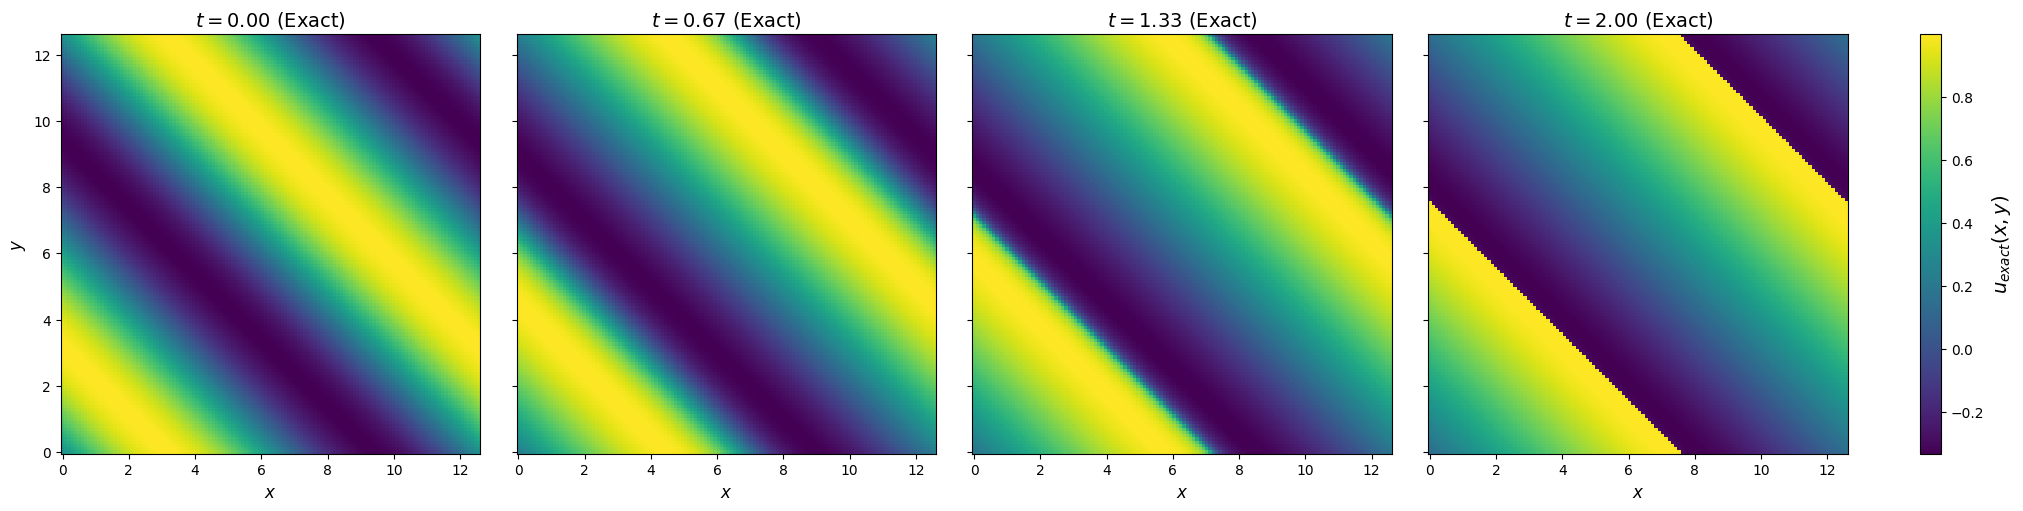

In [14]:
import numpy as np
import matplotlib.pyplot as plt
import os

# ==========================================
# 1. Load Data
# ==========================================
file_path = path_A

if not os.path.exists(file_path):
    raise FileNotFoundError(f"Could not find data file at: {file_path}")

data = np.load(file_path)
t = data['t']      # Shape: (4,) -> [0.0, 0.67, 1.33, 2.0]
x = data['x']      # Shape: (128,)
y = data['y']      # Shape: (128,)
u = data['usol']   # Shape: (4, 128, 128) -> (Time, X, Y)

print(f"Loaded Analytical Solution.")
print(f"Shape: {u.shape} (Time, X, Y)")
print(f"Time steps: {t}")

# ==========================================
# 2. Setup Plotting Grid
# ==========================================
# indexing='ij' ensures X[i,j] corresponds to x[i] and Y[i,j] corresponds to y[j]
# This aligns perfectly with the (Time, X, Y) convention from your solver.
X, Y = np.meshgrid(x, y, indexing='ij')

# ==========================================
# 3. Visualization (1x4 Grid)
# ==========================================
fig, axes = plt.subplots(1, 4, figsize=(20, 5), constrained_layout=True)

# Determine global color limits to highlight shock evolution clearly
vmin, vmax = np.min(u), np.max(u)

for i in range(len(t)):
    ax = axes[i]
    t_curr = t[i]
    u_curr = u[i, :, :] # Extract (X, Y) slice
    
    # Plotting
    c = ax.pcolormesh(X, Y, u_curr, cmap='viridis', 
                      vmin=vmin, vmax=vmax, shading='auto')
    
    # Formatting
    ax.set_title(f"$t = {t_curr:.2f}$ (Exact)", fontsize=14)
    ax.set_aspect('equal')
    ax.set_xlabel("$x$", fontsize=12)
    
    if i == 0:
        ax.set_ylabel("$y$", fontsize=12)
    else:
        # Hide y-ticks for inner plots
        ax.set_yticklabels([])

# Add a single colorbar
cbar = fig.colorbar(c, ax=axes, orientation='vertical', fraction=0.02, pad=0.04)
cbar.set_label("$u_{exact}(x,y)$", fontsize=14)

# ==========================================
# 4. Save Figure
# ==========================================
output_path = "burgers_analytical_summary.png"
plt.savefig(output_path, dpi=300)
print(f"Plot saved to: {output_path}")
plt.show()

Loading data...
Color limits determined from Athena: vmin=-0.33, vmax=1.00
Generating 3x4 plot...
Comparison plot saved to: burgers_ablation_3x4_ref_cmap.png


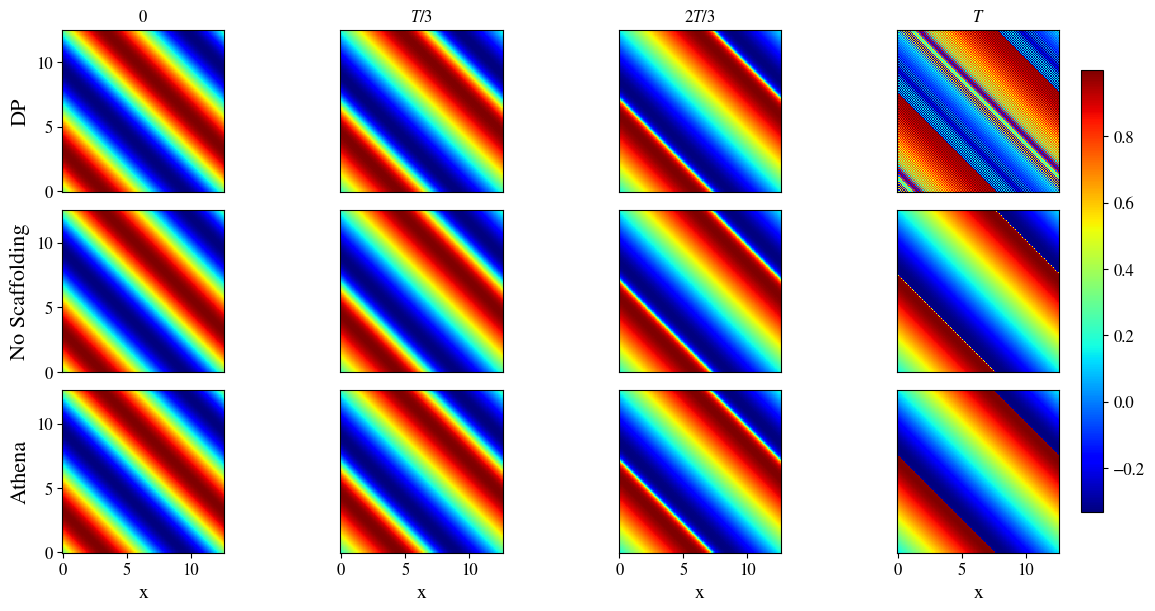

In [52]:
import numpy as np
import matplotlib.pyplot as plt
import os
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.integrate import simpson
from scipy.optimize import brentq
import matplotlib as mpl
from mpl_toolkits.axes_grid1 import make_axes_locatable

# ==============================================================================
# VISUAL CONFIGURATION
# ==============================================================================
mpl.rcParams['mathtext.fontset'] = 'stix'
mpl.rcParams['font.family'] = 'STIXGeneral'
mpl.rcParams['font.size'] = 12
mpl.rcParams['figure.dpi'] = 100
# ==========================================
# 1. Configuration
# ==========================================
paths = {
    "DP": '/users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Examples_analytical_exact/Ablation_Study/Burgers/burgers.npz',
    "No Scaffolding": '/users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/NM_codes/Burgers_Periodic_SinSum/2026_01_10_1309_human/burgers.npz',
    "Athena": '/users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/NM_codes/Burgers_Periodic_SinSumHalf/2025_12_23_1233/burgers.npz'
}

# The keys in the dictionary above will be the Row Labels
row_order = ["DP", "No Scaffolding", "Athena"]
reference_key = "Athena"

# Output filename
output_file = "burgers_ablation_3x4_ref_cmap.png"

# ==========================================
# 2. Helper Functions
# ==========================================
def load_and_prep(name, path):
    """
    Loads .npz data and normalizes the shape to (Time, X, Y).
    Returns: t, X, Y, u_norm
    """
    if not os.path.exists(path):
        raise FileNotFoundError(f"File not found for {name}: {path}")
        
    data = np.load(path)
    
    # Extract coordinates
    t = data['t']
    x = data['x']
    y = data['y']
    
    # Meshgrid for plotting (indexing='ij' matches matrix notation)
    X, Y = np.meshgrid(x, y, indexing='ij')
    
    # Handle Solution Shape variations
    if 'usol' in data:
        raw_u = data['usol']
    elif 'u' in data:
        raw_u = data['u']
    else:
        raise KeyError(f"Could not find solution key ('u' or 'usol') in {name}")
    
    # Normalize shape
    shape = raw_u.shape
    if shape[0] == len(t): 
        u_norm = raw_u
    elif shape[-1] == len(t):
        u_norm = np.transpose(raw_u, (2, 0, 1))
    else:
        raise ValueError(f"Shape mismatch for {name}. t={len(t)}, u={shape}")
        
    return t, X, Y, u_norm

def get_indices(t_array):
    """
    Returns indices for t=0, t=T/3, t=2T/3, t=T
    """
    T_final = t_array[-1]
    targets = [0.0, T_final/3.0, 2.0*T_final/3.0, T_final]
    
    indices = []
    for target in targets:
        # Find index of time closest to target
        idx = (np.abs(t_array - target)).argmin()
        indices.append(idx)
    return indices

# ==========================================
# 3. Main Plotting Logic
# ==========================================
fig, axes = plt.subplots(3, 4, figsize=(12, 6), constrained_layout=True)

loaded_data = {}

# --- Step 1: Load Data ---
print("Loading data...")
for name in row_order:
    path = paths[name]
    t, X, Y, u = load_and_prep(name, path)
    loaded_data[name] = (t, X, Y, u)

# --- Step 2: Determine Color Limits from Reference (Athena) ---
if reference_key in loaded_data:
    _, _, _, u_ref = loaded_data[reference_key]
    global_vmin = np.min(u_ref)
    global_vmax = np.max(u_ref)
    print(f"Color limits determined from {reference_key}: vmin={global_vmin:.2f}, vmax={global_vmax:.2f}")
else:
    # Fallback if reference key is wrong
    print(f"Warning: Reference key '{reference_key}' not found. Using global min/max.")
    global_vmin = 1e9
    global_vmax = -1e9
    for name in row_order:
        _, _, _, u = loaded_data[name]
        global_vmin = min(global_vmin, np.min(u))
        global_vmax = max(global_vmax, np.max(u))

# --- Step 3: Plotting ---
print("Generating 3x4 plot...")

for row_idx, name in enumerate(row_order):
    t, X, Y, u = loaded_data[name]
    indices = get_indices(t)
    
    for col_idx, time_idx in enumerate(indices):
        ax = axes[row_idx, col_idx]
        
        # Extract 2D slice
        u_slice = u[time_idx]
        t_val = t[time_idx]
        
        # Plot Heatmap using Fixed Limits
        pcm = ax.pcolormesh(X, Y, u_slice, cmap='jet', 
                            vmin=global_vmin, vmax=global_vmax, shading='auto')
        
        ax.set_aspect('equal')
        
        # --- Labels and Titles ---
        
        # Column Titles (Only on top row)
        if row_idx == 0:
            target_frac = ["0", "T/3", "2T/3", "T"][col_idx]
            ax.set_title(f"${target_frac}$", fontsize=12)
            
        # Row Labels
        if col_idx == 0:
            ax.set_ylabel(name, fontsize=16)
        else:
            ax.set_yticks([]) # Hide ticks on inner columns
            
        # X-axis labels (Only on bottom row)
        if row_idx == 2:
            ax.set_xlabel("x", fontsize=14)
        else:
            ax.set_xticks([]) # Hide ticks on upper rows

# Add Colorbar
cbar = fig.colorbar(pcm, ax=axes, orientation='vertical', fraction=0.02, pad=0.02)

# ==========================================
# 4. Save
# ==========================================
plt.savefig(output_file, dpi=300, bbox_inches='tight')
print(f"Comparison plot saved to: {output_file}")
plt.show()

Loading data...
Color limits fixed to Athena: [-0.333, 1.000]
Generating 3x4 plot with row-specific colorbars...
Comparison plot saved to: burgers_ablation_3x4_ref_cmap.png


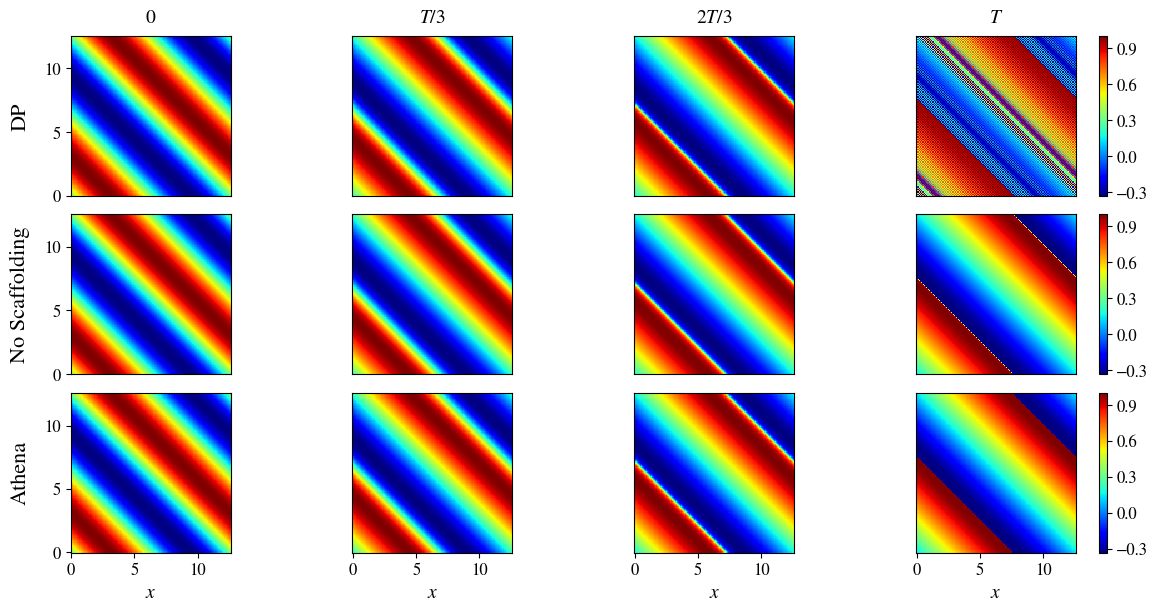

In [65]:
import numpy as np
import matplotlib.pyplot as plt
import os
import matplotlib as mpl
from mpl_toolkits.axes_grid1 import make_axes_locatable

# ==============================================================================
# VISUAL CONFIGURATION
# ==============================================================================
mpl.rcParams['mathtext.fontset'] = 'stix'
mpl.rcParams['font.family'] = 'STIXGeneral'
mpl.rcParams['font.size'] = 12
mpl.rcParams['figure.dpi'] = 100

# ==========================================
# 1. Configuration
# ==========================================
paths = {
    "DP": '/users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Examples_analytical_exact/Ablation_Study/Burgers/burgers.npz',
    "No Scaffolding": '/users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/NM_codes/Burgers_Periodic_SinSum/2026_01_10_1309_human/burgers.npz',
    "Athena": '/users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/NM_codes/Burgers_Periodic_SinSumHalf/2025_12_23_1233/burgers.npz'
}

# The keys in the dictionary above will be the Row Labels
row_order = ["DP", "No Scaffolding", "Athena"]
reference_key = "Athena"

# Output filename
output_file = "burgers_ablation_3x4_ref_cmap.png"

# ==========================================
# 2. Helper Functions
# ==========================================
def load_and_prep(name, path):
    """
    Loads .npz data and normalizes the shape to (Time, X, Y).
    Returns: t, X, Y, u_norm
    """
    if not os.path.exists(path):
        raise FileNotFoundError(f"File not found for {name}: {path}")
        
    data = np.load(path)
    
    # Extract coordinates
    t = data['t']
    x = data['x']
    y = data['y']
    
    # Meshgrid for plotting (indexing='ij' matches matrix notation)
    X, Y = np.meshgrid(x, y, indexing='ij')
    
    # Handle Solution Shape variations
    if 'usol' in data:
        raw_u = data['usol']
    elif 'u' in data:
        raw_u = data['u']
    else:
        raise KeyError(f"Could not find solution key ('u' or 'usol') in {name}")
    
    # Normalize shape
    shape = raw_u.shape
    if shape[0] == len(t): 
        u_norm = raw_u
    elif shape[-1] == len(t):
        u_norm = np.transpose(raw_u, (2, 0, 1))
    else:
        raise ValueError(f"Shape mismatch for {name}. t={len(t)}, u={shape}")
        
    return t, X, Y, u_norm

def get_indices(t_array):
    """
    Returns indices for t=0, t=T/3, t=2T/3, t=T
    """
    T_final = t_array[-1]
    targets = [0.0, T_final/3.0, 2.0*T_final/3.0, T_final]
    
    indices = []
    for target in targets:
        idx = (np.abs(t_array - target)).argmin()
        indices.append(idx)
    return indices

# ==========================================
# 3. Main Plotting Logic
# ==========================================
# Load Data first
loaded_data = {}
print("Loading data...")
for name in row_order:
    path = paths[name]
    t, X, Y, u = load_and_prep(name, path)
    loaded_data[name] = (t, X, Y, u)

# Determine Color Limits ONLY from Reference (Athena)
if reference_key in loaded_data:
    _, _, _, u_ref = loaded_data[reference_key]
    global_vmin = np.min(u_ref)
    global_vmax = np.max(u_ref)
    print(f"Color limits fixed to {reference_key}: [{global_vmin:.3f}, {global_vmax:.3f}]")
else:
    print(f"Warning: Reference key '{reference_key}' not found.")
    global_vmin, global_vmax = -1, 1

# Generate Plot
fig, axes = plt.subplots(3, 4, figsize=(12, 6), constrained_layout=True)

print("Generating 3x4 plot with row-specific colorbars...")

for row_idx, name in enumerate(row_order):
    t, X, Y, u = loaded_data[name]
    indices = get_indices(t)
    
    row_im = None # Store mappable for colorbar
    
    for col_idx, time_idx in enumerate(indices):
        ax = axes[row_idx, col_idx]
        
        # Extract 2D slice
        u_slice = u[time_idx]
        
        # Plot Heatmap using GLOBAL FIXED LIMITS
        row_im = ax.pcolormesh(X, Y, u_slice, cmap='jet', 
                               vmin=global_vmin, vmax=global_vmax, shading='auto')
        
        ax.set_aspect('equal')
        
        # --- Labels and Titles ---
        # Column Titles (Top Row Only)
        if row_idx == 0:
            target_frac = ["0", "T/3", "2T/3", "T"][col_idx]
            ax.set_title(f"${target_frac}$", fontsize=14, pad=10)
            
        # Row Labels (Left Column Only)
        if col_idx == 0:
            ax.set_ylabel(name, fontsize=16, labelpad=10)
        
        # X/Y Ticks
        # Hide Y ticks for all except first column
        if col_idx != 0:
            ax.set_yticks([])
            
        # Hide X ticks for all except last row
        if row_idx != 2:
            ax.set_xticks([])
        else:
            ax.set_xlabel("$x$", fontsize=14)

    # --- ROW-SPECIFIC COLORBAR ---
    # Placed on the right of the specific row
    cbar = fig.colorbar(row_im, ax=axes[row_idx, :], orientation='vertical', 
                        fraction=0.02, pad=0.02)
    # Optional: reduce number of ticks to avoid crowding
    cbar.locator = mpl.ticker.MaxNLocator(nbins=5)
    cbar.update_ticks()

# ==========================================
# 4. Save
# ==========================================
plt.savefig(output_file, dpi=300, bbox_inches='tight')
print(f"Comparison plot saved to: {output_file}")

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.interpolate import griddata
import glob
import os

# ==============================================================================
# 1. VISUAL CONFIGURATION (STIX Fonts)
# ==============================================================================
mpl.rcParams['mathtext.fontset'] = 'stix'
mpl.rcParams['font.family'] = 'STIXGeneral'
mpl.rcParams['font.size'] = 16
mpl.rcParams['figure.dpi'] = 100

# ==============================================================================
# 2. CONFIGURATION
# ==============================================================================
INPUT_DIR_1 = "/users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/NM_codes/CompressibleEuler_Periodic_Reflective_SmoothedInterface_ICs/2025_12_06_2123/data_npz/"
INPUT_DIR_2 = "/users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/NM_codes/CompressibleEuler_PeriodicReflective_SmoothedInterface/2026_01_10_1232/rti_output/"
OUTPUT_FILE = "RT_comparison.png"

# Grid Resolution (Matches 1:4 Domain Aspect Ratio)
NX, NY = 300, 1200
DOMAIN = [0.0, 0.25, 0.0, 1.0] # [x_min, x_max, y_min, y_max]

# ==============================================================================
# 3. HELPER: REGRIDDING
# ==============================================================================
def regrid_data(x, y, z, nx, ny, domain):
    """
    Converts scattered AMR data to a uniform grid using fast histogram binning.
    Fills empty pixels (holes) using nearest-neighbor interpolation.
    """
    x_edges = np.linspace(domain[0], domain[1], nx + 1)
    y_edges = np.linspace(domain[2], domain[3], ny + 1)

    # Fast Binning
    weighted_hist, _, _ = np.histogram2d(y, x, bins=[y_edges, x_edges], weights=z)
    count_hist, _, _ = np.histogram2d(y, x, bins=[y_edges, x_edges])

    # Average
    with np.errstate(divide='ignore', invalid='ignore'):
        grid = weighted_hist / count_hist

    # Fill Holes
    if np.any(np.isnan(grid)):
        yy, xx = np.mgrid[0:ny, 0:nx]
        valid_mask = ~np.isnan(grid)
        
        points = np.column_stack((yy[valid_mask], xx[valid_mask]))
        values = grid[valid_mask]
        target_points = np.column_stack((yy[~valid_mask], xx[~valid_mask]))
        
        if len(target_points) > 0 and len(values) > 0:
            filled_values = griddata(points, values, target_points, method='nearest')
            grid[~valid_mask] = filled_values

    return grid

# ==============================================================================
# 4. HELPER: LOAD DATASET AND GET GLOBAL LIMITS
# ==============================================================================
def load_dataset(input_dir, num_snapshots=8):
    """
    Load files and compute global limits for a dataset.
    Returns: files, times, global_lims
    """
    search_path = os.path.join(input_dir, "*.npz")
    files = sorted(glob.glob(search_path))
    
    if not files:
        print(f"ERROR: No .npz files found in {input_dir}")
        return None, None, None
    
    print(f"Dataset {input_dir}: Found {len(files)} snapshots.")
    
    # Get times
    times_all = []
    for f in files:
        with np.load(f) as data:
            times_all.append(float(data['t']))
    times_all = np.array(times_all)
    
    # Compute global limits
    print(f"  Computing global limits...")
    global_lims = {
        'rho': [np.inf, -np.inf],
        'u':   [np.inf, -np.inf],
    }
    
    for f in files[::5]:
        data = np.load(f)
        for var in ['rho', 'u']:
            vals = data[var].flatten()
            v_min, v_max = np.min(vals), np.max(vals)
            global_lims[var][0] = min(global_lims[var][0], v_min)
            global_lims[var][1] = max(global_lims[var][1], v_max)
    
    print(f"  Global Limits: {global_lims}")
    
    # Select equidistant snapshots
    t_end = np.max(times_all)
    targets = np.linspace(0.0, t_end, num_snapshots)
    indices = [np.argmin(np.abs(times_all - t)) for t in targets]
    
    selected_files = [files[i] for i in indices]
    selected_times = [times_all[i] for i in indices]
    
    return selected_files, selected_times, global_lims


Dataset /users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/NM_codes/CompressibleEuler_Periodic_Reflective_SmoothedInterface_ICs/2025_12_06_2123/data_npz/: Found 30 snapshots.
Dataset /users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/NM_codes/CompressibleEuler_PeriodicReflective_SmoothedInterface/2026_01_10_1232/rti_output/: Found 80 snapshots.

Combined Density Limits: {'rho': [np.float64(0.7857737735068588), np.float64(2.508463393259111)]}
Saving to RT_comparison_density_10cols_finalT.png...
Done.


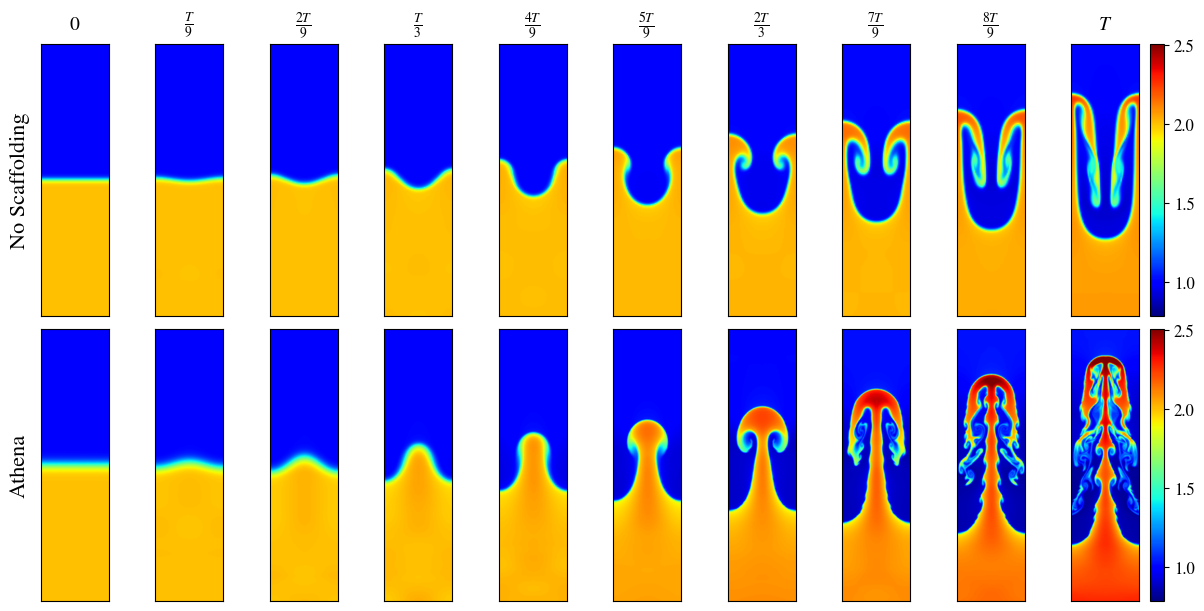

In [66]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.interpolate import griddata
import glob
import os

# ==============================================================================
# 1. VISUAL CONFIGURATION
# ==============================================================================
mpl.rcParams['mathtext.fontset'] = 'stix'
mpl.rcParams['font.family'] = 'STIXGeneral'
mpl.rcParams['font.size'] = 12
mpl.rcParams['figure.dpi'] = 100

# ==============================================================================
# 2. CONFIGURATION
# ==============================================================================
INPUT_DIR_1 = "/users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/NM_codes/CompressibleEuler_Periodic_Reflective_SmoothedInterface_ICs/2025_12_06_2123/data_npz/"
INPUT_DIR_2 = "/users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/NM_codes/CompressibleEuler_PeriodicReflective_SmoothedInterface/2026_01_10_1232/rti_output/"
OUTPUT_FILE = "RT_comparison_density_10cols_finalT.png"

# Grid Resolution
NX, NY = 300, 1200
DOMAIN = [0.0, 0.25, 0.0, 1.0] 

# ==============================================================================
# 3. HELPER: REGRIDDING
# ==============================================================================
def regrid_data(x, y, z, nx, ny, domain):
    x_edges = np.linspace(domain[0], domain[1], nx + 1)
    y_edges = np.linspace(domain[2], domain[3], ny + 1)

    weighted_hist, _, _ = np.histogram2d(y, x, bins=[y_edges, x_edges], weights=z)
    count_hist, _, _ = np.histogram2d(y, x, bins=[y_edges, x_edges])

    with np.errstate(divide='ignore', invalid='ignore'):
        grid = weighted_hist / count_hist

    if np.any(np.isnan(grid)):
        yy, xx = np.mgrid[0:ny, 0:nx]
        valid_mask = ~np.isnan(grid)
        if np.count_nonzero(valid_mask) > 0:
            points = np.column_stack((yy[valid_mask], xx[valid_mask]))
            values = grid[valid_mask]
            target_points = np.column_stack((yy[~valid_mask], xx[~valid_mask]))
            filled_values = griddata(points, values, target_points, method='nearest')
            grid[~valid_mask] = filled_values
    return grid

# ==============================================================================
# 4. HELPER: LOAD DATASET
# ==============================================================================
def load_dataset(input_dir, num_snapshots=10):
    search_path = os.path.join(input_dir, "*.npz")
    files = sorted(glob.glob(search_path))
    
    if not files: return None, None, None
    
    print(f"Dataset {input_dir}: Found {len(files)} snapshots.")
    
    times_all = []
    for f in files:
        with np.load(f) as data:
            times_all.append(float(data['t']))
    times_all = np.array(times_all)
    
    global_lims = {'rho': [np.inf, -np.inf]}
    
    for f in files[::5]:
        with np.load(f) as data:
            vals = data['rho'].flatten()
            global_lims['rho'][0] = min(global_lims['rho'][0], np.min(vals))
            global_lims['rho'][1] = max(global_lims['rho'][1], np.max(vals))
    
    t_end = np.max(times_all)
    
    # === STOP AT T with 10 Points ===
    # 10 points inclusive means 9 intervals.
    targets = np.linspace(0.0, t_end, num_snapshots)
    
    indices = [np.argmin(np.abs(times_all - t)) for t in targets]
    
    selected_files = [files[i] for i in indices]
    selected_times = [times_all[i] for i in indices]
    
    return selected_files, selected_times, global_lims

# ==============================================================================
# 5. MAIN EXECUTION
# ==============================================================================
def main():
    num_snapshots = 10  # UPDATED TO 10
    
    files_1, times_1, lims_1 = load_dataset(INPUT_DIR_1, num_snapshots)
    files_2, times_2, lims_2 = load_dataset(INPUT_DIR_2, num_snapshots)
    
    if files_1 is None or files_2 is None: return

    # Combine limits
    combined_lims = {
        'rho': [min(lims_1['rho'][0], lims_2['rho'][0]), 
                max(lims_1['rho'][1], lims_2['rho'][1])]
    }
    print(f"\nCombined Density Limits: {combined_lims}")

    # --------------------------------------------------------------------------
    # PLOTTING
    # --------------------------------------------------------------------------
    # Increased width to accommodate 10 columns
    fig, axes = plt.subplots(2, num_snapshots, figsize=(12, 6), constrained_layout=True)
    
    row_configs = [
        # ROW 0: Dataset 2
        {'dataset_idx': 1, 'var': 'rho', 'label': "No Scaffolding", 'cmap': 'jet'},
        # ROW 1: Dataset 1
        {'dataset_idx': 0, 'var': 'rho', 'label': "Athena",         'cmap': 'jet'}
    ]
    
    datasets = [
        {'files': files_1, 'times': times_1}, # Index 0
        {'files': files_2, 'times': times_2}  # Index 1
    ]
    
    # Time Labels for 10 Snapshots (0 to T, step T/9)
    # 0, 1/9, 2/9, 3/9(1/3), 4/9, 5/9, 6/9(2/3), 7/9, 8/9, 1
    time_labels = [
        f"$0$", 
        r"$\frac{T}{9}$", 
        r"$\frac{2T}{9}$", 
        r"$\frac{T}{3}$", 
        r"$\frac{4T}{9}$", 
        r"$\frac{5T}{9}$", 
        r"$\frac{2T}{3}$", 
        r"$\frac{7T}{9}$", 
        r"$\frac{8T}{9}$", 
        f"$T$"
    ]
    
    for row_idx, config in enumerate(row_configs):
        dset = datasets[config['dataset_idx']]
        var = config['var']
        vmin, vmax = combined_lims[var]
        
        row_im = None
        
        for col_idx in range(num_snapshots):
            ax = axes[row_idx, col_idx]
            
            f_path = dset['files'][col_idx]
            data = np.load(f_path)
            
            # --- SHAPE DETECTION LOGIC ---
            if data['x'].ndim == 1 and data['rho'].ndim == 2:
                grid = data[var].T
            else:
                x = data['x'].flatten()
                y = data['y'].flatten()
                z = data[var].flatten()
                grid = regrid_data(x, y, z, NX, NY, DOMAIN)
            
            # Plot
            row_im = ax.imshow(grid, origin='lower', extent=DOMAIN, 
                               cmap=config['cmap'], interpolation='bilinear',
                               vmin=vmin, vmax=vmax)
            
            if row_idx == 0:
                ax.set_title(time_labels[col_idx], pad=10, fontsize=14)
            
            # === Y LABEL ADJUSTMENT ===
            if col_idx == 0:
                ax.set_ylabel(config['label'], rotation=90, size=16, labelpad=15, va='center')
            
            ax.set_xticks([])
            ax.set_yticks([])

        cbar = fig.colorbar(row_im, ax=axes[row_idx, :], orientation='vertical', 
                            fraction=0.015, pad=0.01, aspect=20)
        cbar.locator = mpl.ticker.MaxNLocator(nbins=4)
        cbar.update_ticks()

    print(f"Saving to {OUTPUT_FILE}...")
    plt.savefig(OUTPUT_FILE, dpi=300, bbox_inches='tight')
    print("Done.")

if __name__ == "__main__":
    main()

Loading Burgers Data...
Loading RTI Data...
Saving combined figure to Combined_Ablation_10x12.png...
Done.


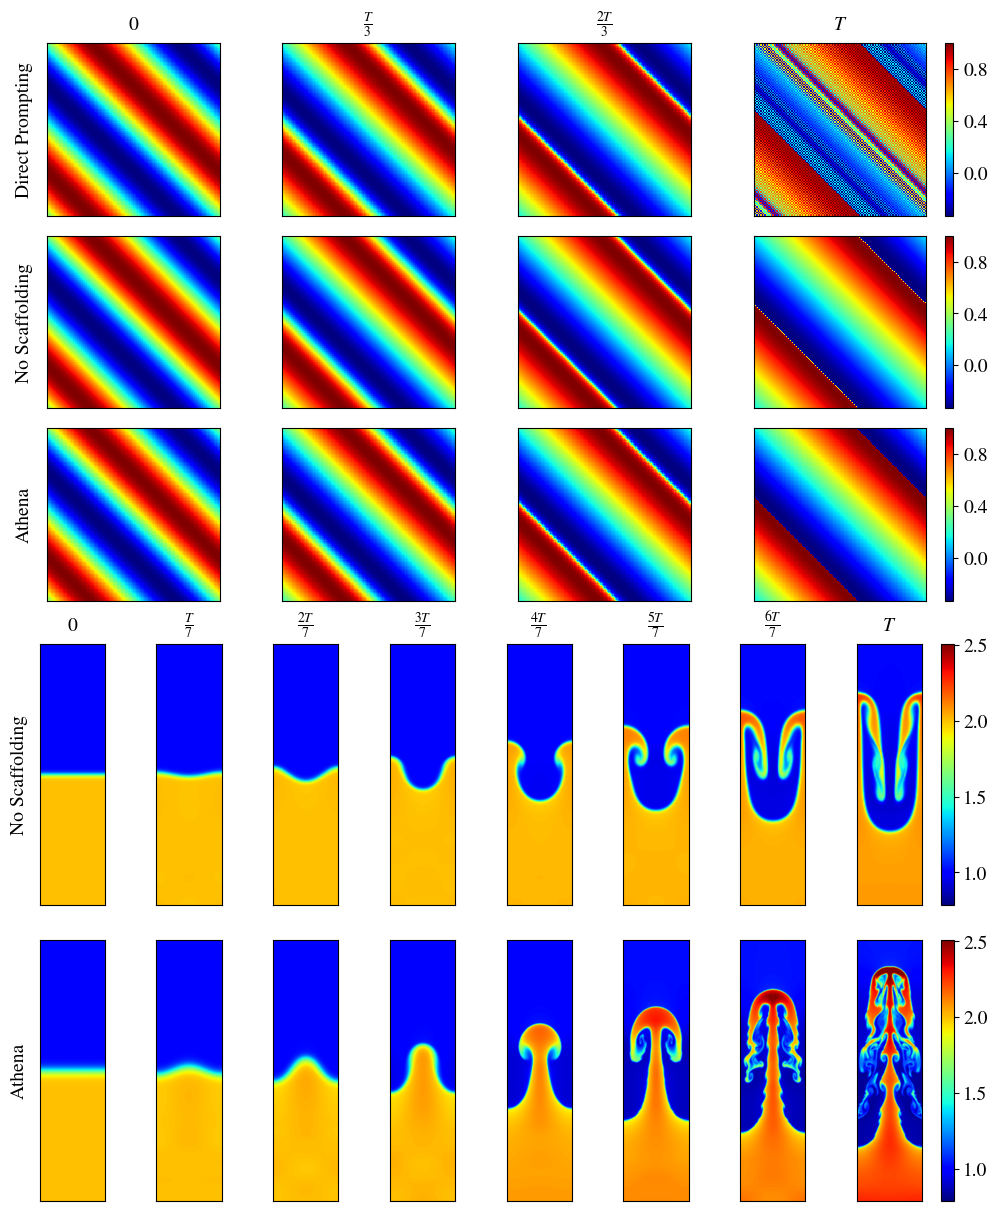

In [74]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import os
import glob
from scipy.interpolate import griddata

# ==============================================================================
# 1. VISUAL CONFIGURATION
# ==============================================================================
mpl.rcParams['mathtext.fontset'] = 'stix'
mpl.rcParams['font.family'] = 'STIXGeneral'
mpl.rcParams['font.size'] = 14
mpl.rcParams['figure.dpi'] = 100

# ==============================================================================
# 2. CONFIGURATION PATHS
# ==============================================================================
# --- Burgers Paths ---
BURGERS_PATHS = {
    "Direct Prompting": '/users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Examples_analytical_exact/Ablation_Study/Burgers/burgers.npz',
    "No Scaffolding": '/users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/NM_codes/Burgers_Periodic_SinSum/2026_01_10_1309_human/burgers.npz',
    "Athena": '/users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/NM_codes/Burgers_Periodic_SinSumHalf/2025_12_23_1233/burgers.npz'
}
BURGERS_ROWS = ["Direct Prompting", "No Scaffolding", "Athena"]
BURGERS_REF = "Athena"

# --- RTI Paths ---
RTI_PATH_ATHENA = "/users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/NM_codes/CompressibleEuler_Periodic_Reflective_SmoothedInterface_ICs/2025_12_06_2123/data_npz/"
RTI_PATH_NOSCAFFOLD = "/users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/NM_codes/CompressibleEuler_PeriodicReflective_SmoothedInterface/2026_01_10_1232/rti_output/"
RTI_NX, RTI_NY = 300, 1200
RTI_DOMAIN = [0.0, 0.25, 0.0, 1.0]

OUTPUT_FILE = "Combined_Ablation_10x12.png"

# ==============================================================================
# 3. DATA LOADING HELPERS
# ==============================================================================

def load_burgers_data(name, path):
    if not os.path.exists(path): return None, None, None, None
    data = np.load(path)
    t, x, y = data['t'], data['x'], data['y']
    X, Y = np.meshgrid(x, y, indexing='ij')
    
    if 'usol' in data: raw_u = data['usol']
    elif 'u' in data: raw_u = data['u']
    else: return None, None, None, None
    
    if raw_u.shape[0] == len(t): u_norm = raw_u
    elif raw_u.shape[-1] == len(t): u_norm = np.transpose(raw_u, (2, 0, 1))
    else: return None, None, None, None
    
    return t, X, Y, u_norm

def regrid_rti(x, y, z, nx, ny, domain):
    x_edges = np.linspace(domain[0], domain[1], nx + 1)
    y_edges = np.linspace(domain[2], domain[3], ny + 1)
    
    weighted, _, _ = np.histogram2d(y, x, bins=[y_edges, x_edges], weights=z)
    counts, _, _ = np.histogram2d(y, x, bins=[y_edges, x_edges])
    
    with np.errstate(divide='ignore', invalid='ignore'):
        grid = weighted / counts
        
    if np.any(np.isnan(grid)):
        yy, xx = np.mgrid[0:ny, 0:nx]
        valid_mask = ~np.isnan(grid)
        if np.count_nonzero(valid_mask) > 0:
            points = np.column_stack((yy[valid_mask], xx[valid_mask]))
            values = grid[valid_mask]
            target = np.column_stack((yy[~valid_mask], xx[~valid_mask]))
            grid[~valid_mask] = griddata(points, values, target, method='nearest')
    return grid

def load_rti_dataset(input_dir, num_snapshots):
    files = sorted(glob.glob(os.path.join(input_dir, "*.npz")))
    if not files: return None, None, None
    
    times = []
    for f in files:
        with np.load(f) as data: times.append(float(data['t']))
    times = np.array(times)
    
    rho_lims = [np.inf, -np.inf]
    # Check bounds
    for f in files[::5]:
        with np.load(f) as data:
            vals = data['rho'].flatten()
            rho_lims[0] = min(rho_lims[0], np.min(vals))
            rho_lims[1] = max(rho_lims[1], np.max(vals))
            
    # Select Snapshots (0 to T inclusive)
    targets = np.linspace(0.0, np.max(times), num_snapshots)
    indices = [np.argmin(np.abs(times - t)) for t in targets]
    
    return [files[i] for i in indices], [times[i] for i in indices], rho_lims

# ==============================================================================
# 4. MAIN PLOTTING
# ==============================================================================
def main():
    # --- BURGERS DATA ---
    print("Loading Burgers Data...")
    burgers_data = {}
    for name in BURGERS_ROWS:
        burgers_data[name] = load_burgers_data(name, BURGERS_PATHS[name])
    
    b_ref = burgers_data[BURGERS_REF][3]
    b_vmin, b_vmax = np.min(b_ref), np.max(b_ref)

    # --- RTI DATA ---
    print("Loading RTI Data...")
    RTI_COLS = 8  # CHANGED TO 8 COLUMNS
    rti_1 = load_rti_dataset(RTI_PATH_ATHENA, RTI_COLS)     # Athena
    rti_2 = load_rti_dataset(RTI_PATH_NOSCAFFOLD, RTI_COLS) # No Scaffolding
    
    r_vmin = min(rti_1[2][0], rti_2[2][0])
    r_vmax = max(rti_1[2][1], rti_2[2][1])

    # --------------------------------------------------------------------------
    # FIGURE SETUP
    # --------------------------------------------------------------------------
    fig = plt.figure(figsize=(10, 12), constrained_layout=True)
    outer_gs = fig.add_gridspec(2, 1, hspace=0.15, height_ratios=[1, 1])
    
    # ==========================================================================
    # TOP PANEL: BURGERS (3 Rows x 4 Cols)
    # ==========================================================================
    gs_top = outer_gs[0].subgridspec(3, 4, wspace=0.05, hspace=0.05)
    ax_top_arr = gs_top.subplots()
    
    burgers_times = [r"$0$", r"$\frac{T}{3}$", r"$\frac{2T}{3}$", r"$T$"]
    
    for row_idx, name in enumerate(BURGERS_ROWS):
        t, X, Y, u = burgers_data[name]
        t_targets = np.linspace(0, t[-1], 4)
        indices = [np.argmin(np.abs(t - val)) for val in t_targets]
        
        row_im = None
        for col_idx, time_idx in enumerate(indices):
            ax = ax_top_arr[row_idx, col_idx]
            row_im = ax.pcolormesh(X, Y, u[time_idx], cmap='jet', 
                                   vmin=b_vmin, vmax=b_vmax, shading='auto')
            ax.set_aspect('equal')
            
            # TITLE
            if row_idx == 0: 
                ax.set_title(burgers_times[col_idx], pad=10, fontsize=14)
            
            # LABELS (UPDATED: Remove numbers and X labels)
            if col_idx == 0: 
                ax.set_ylabel(name, fontsize=14, labelpad=10)
            
            # STRICTLY REMOVE ALL TICKS AND X/Y COORDINATE LABELS
            ax.set_xticks([])
            ax.set_yticks([])
            ax.set_xlabel("")
            # Note: We kept set_ylabel(name) above because it acts as the Row Title

        cbar = fig.colorbar(row_im, ax=ax_top_arr[row_idx, :], location='right', 
                            fraction=0.015, pad=0.02)
        cbar.locator = mpl.ticker.MaxNLocator(nbins=4)
        cbar.update_ticks()

    # ==========================================================================
    # BOTTOM PANEL: RTI (2 Rows x 8 Cols)
    # ==========================================================================
    gs_bot = outer_gs[1].subgridspec(2, RTI_COLS, wspace=0.05, hspace=0.05)
    ax_bot_arr = gs_bot.subplots()
    
    rti_configs = [
        {'data': rti_2, 'label': "No Scaffolding"}, 
        {'data': rti_1, 'label': "Athena"}          
    ]
    
    # 8 Time Labels: 0 to T, step T/7
    rti_time_lbls = [
        f"$0$", 
        r"$\frac{T}{7}$", 
        r"$\frac{2T}{7}$", 
        r"$\frac{3T}{7}$", 
        r"$\frac{4T}{7}$", 
        r"$\frac{5T}{7}$", 
        r"$\frac{6T}{7}$", 
        f"$T$"
    ]

    for row_idx, config in enumerate(rti_configs):
        files, _, _ = config['data']
        
        row_im = None
        for col_idx in range(RTI_COLS):
            ax = ax_bot_arr[row_idx, col_idx]
            
            d = np.load(files[col_idx])
            if d['x'].ndim == 1 and d['rho'].ndim == 2: 
                grid = d['rho'].T
            else: 
                grid = regrid_rti(d['x'].flatten(), d['y'].flatten(), d['rho'].flatten(), 
                                  RTI_NX, RTI_NY, RTI_DOMAIN)
            
            row_im = ax.imshow(grid, origin='lower', extent=RTI_DOMAIN, cmap='jet',
                               vmin=r_vmin, vmax=r_vmax, interpolation='bilinear')
            
            # TITLE
            if row_idx == 0: 
                ax.set_title(rti_time_lbls[col_idx], pad=10, fontsize=14)
            
            # LABEL
            if col_idx == 0: 
                ax.set_ylabel(config['label'], rotation=90, size=14, labelpad=15, va='center')
            
            ax.set_xticks([])
            ax.set_yticks([])

        cbar = fig.colorbar(row_im, ax=ax_bot_arr[row_idx, :], location='right', 
                            fraction=0.015, pad=0.02, aspect=20)
        cbar.locator = mpl.ticker.MaxNLocator(nbins=4)
        cbar.update_ticks()

    print(f"Saving combined figure to {OUTPUT_FILE}...")
    plt.savefig(OUTPUT_FILE, dpi=300, bbox_inches='tight')
    print("Done.")

if __name__ == "__main__":
    main()